# Boston Housing EDA: A Friendly Survival Guide

হ্যালো প্রোগ্রামারস! **Week 01 Conceptual Session**-এর কাজ হিসেবে আমরা **Pandas + EDA** করবো — টেবিল খুলে দেখব, মিসিং ধরব, চার্ট বানাব।

Dataset: [Boston House Prices on Kaggle](https://www.kaggle.com/datasets/vikrishnan/boston-house-prices)  
File: `housing.csv` (506 rows, 14 columns, whitespace-separated, **no header row**).

This is **Exploratory Data Analysis**, not "fit a model and buy a house in Boston."

> "You cannot negotiate rent with `plt.scatter`. But EDA tells you which features actually matter before the model lies politely."

**How to use this:**
- Run top to bottom. Plots reuse `df`.
- Read the joke. Then look at the chart.
- Practice at the end is empty on purpose.

**Map**
1. What is EDA  
2. Analytical view of a dataset  
3. Input screening  
4. Statistical profiling  
5. Univariate — categorical (`CHAS`)  
6. Univariate — numerical (`RM`, `LSTAT`, `MEDV`)  
7. Countplot with hue  
8. Barplot (category vs number)  
9. KDE / density  
10. Scatterplot  
11. Y profiling (`MEDV`)  
12. Practice  


In [ ]:
# !pip install pandas matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

BOSTON_COLS = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS",
    "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV",
]

candidates = [
    Path("/content/housing.csv"),
    Path("data/housing.csv"),
]
DATA = next((p for p in candidates if p.exists()), None)
if DATA is None:
    raise FileNotFoundError(
        "Download housing.csv from Kaggle and put it next to this notebook."
    )

df = pd.read_csv(DATA, sep=r'\s+', names=BOSTON_COLS, header=None)
print("loaded:", DATA)
print("shape :", df.shape)
print("Good. 506 neighborhoods. Still cheaper than 2026 rent jokes.")


loaded: /content/housing.csv
shape : (506, 14)
Good. 506 neighborhoods. Still cheaper than 2026 rent jokes.


---

# 1. What is EDA

**EDA** = look at the table before you marry it.

Questions EDA answers cheaply:

- How many rows? What columns?
- What is the **target** (`MEDV` = median home value in $1000s)?
- Which columns are numbers vs categories?
- Any missing values?
- Does river view (`CHAS`) or room count (`RM`) shout in the plots?

Skip EDA and the model will still run. It might learn that row 47 is special because it is row 47.


**Target (Y):** `MEDV` — median house price in **thousands of dollars**.

Example: `MEDV = 24.0` means about **$24,000** (dataset is old; do not move to Boston with this budget).

**Categorical (for us today):** `CHAS` (0/1 = not on Charles River / on river).  
**Numeric stars:** `RM` (rooms), `LSTAT` (% lower status), `NOX`, `AGE`, etc.


# 2. Analytical view of a dataset

First date: `head`, `columns`, `shape`. Do not print 506 rows like homework revenge.


In [ ]:
print("rows, cols:", df.shape)
print("columns   :", df.columns.tolist())
df.head()


rows, cols: (506, 14)
columns   : ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


### Column cheat sheet (short)

| Col | Meaning |
|-----|---------|
| `CRIM` | crime rate by town |
| `RM` | avg number of rooms |
| `AGE` | old homes proportion |
| `DIS` | distance to employment centers |
| `CHAS` | Charles River dummy (0/1) |
| `LSTAT` | % lower status population |
| `MEDV` | **target** — median home value ($1000s) |
| ... | rest are town/industry/tax vibes |

Full names are in the sklearn docs. For EDA, know **target**, **CHAS**, **RM**, **LSTAT**. That is enough to start.


# 3. Input screening

Check dtypes, missing values, duplicates, weird ranges.


In [ ]:
df.info()
print()
print("missing:")
print(df.isna().sum())
print("duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB

missing:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64
duplicate rows: 0


Boston housing in this file: usually **no missing**. If your copy has holes, your download fought someone.

`CHAS` should be only 0 or 1. If you see 2, something imported wrong.


In [ ]:
assert set(df["CHAS"].unique()) <= {0, 1}
print("CHAS counts:\n", df["CHAS"].value_counts())
print("MEDV min/max:", df["MEDV"].min(), df["MEDV"].max())


CHAS counts:
 CHAS
0    471
1     35
Name: count, dtype: int64
MEDV min/max: 5.0 50.0


# 4. Statistical profiling

`describe()` for numbers. This is the table clearing its throat.


In [ ]:
df.describe()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
df.describe(include=["int64"]).T if False else None  # skip trick
print("CHAS as category:")
print(df["CHAS"].value_counts(normalize=True).round(3))


CHAS as category:
CHAS
0    0.931
1    0.069
Name: proportion, dtype: float64


**Read it like a human:**

- `RM` mean ~6 rooms. Not a mansion. Not a shoebox.
- `LSTAT` spread matters — inequality shows up in house prices later.
- `MEDV` max 50 → $50k cap in this dataset. Inflation was not invited.


# 5. Univariate — categorical (`CHAS`)

Univariate = one column. `CHAS`: river or no river. Only 35 river towns. Rare flex.


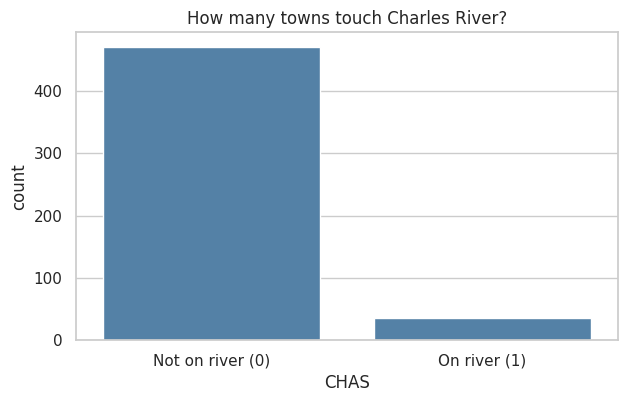

CHAS
0    471
1     35
Name: count, dtype: int64


In [ ]:
sns.countplot(data=df, x="CHAS", color="steelblue")
plt.xticks([0, 1], ["Not on river (0)", "On river (1)"])
plt.title("How many towns touch Charles River?")
plt.show()
print(df["CHAS"].value_counts())


# 6. Univariate — numerical

`RM`, `LSTAT`, and target `MEDV`. Histogram + boxplot = where values live and who is an outlier.


In [ ]:
for col in ["RM", "LSTAT", "MEDV"]:
    print("===", col, "===")
    print(df[col].describe())
    print()


=== RM ===
count    506.000000
mean       6.284634
std        0.702617
min        3.561000
25%        5.885500
50%        6.208500
75%        6.623500
max        8.780000
Name: RM, dtype: float64

=== LSTAT ===
count    506.000000
mean      12.653063
std        7.141062
min        1.730000
25%        6.950000
50%       11.360000
75%       16.955000
max       37.970000
Name: LSTAT, dtype: float64

=== MEDV ===
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64



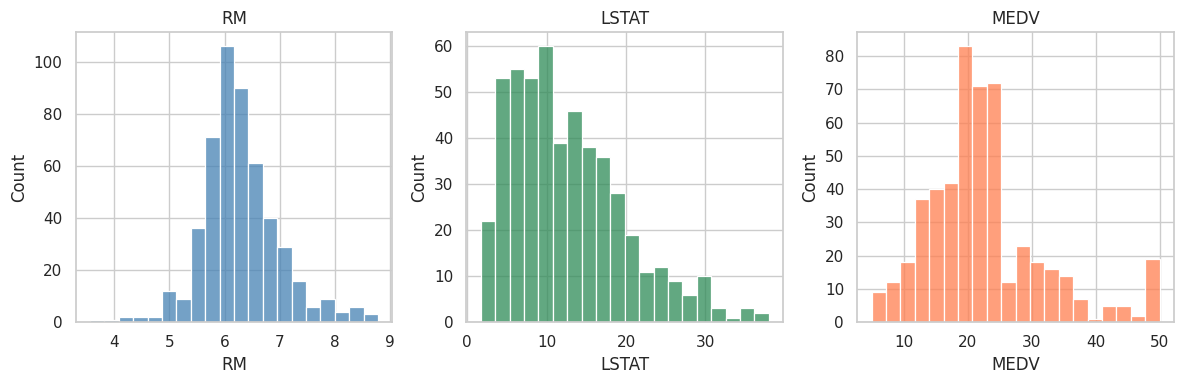

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, color in zip(axes, ["RM", "LSTAT", "MEDV"], ["steelblue", "seagreen", "coral"]):
    sns.histplot(df[col], bins=20, ax=ax, color=color)
    ax.set_title(col)
plt.tight_layout()
plt.show()


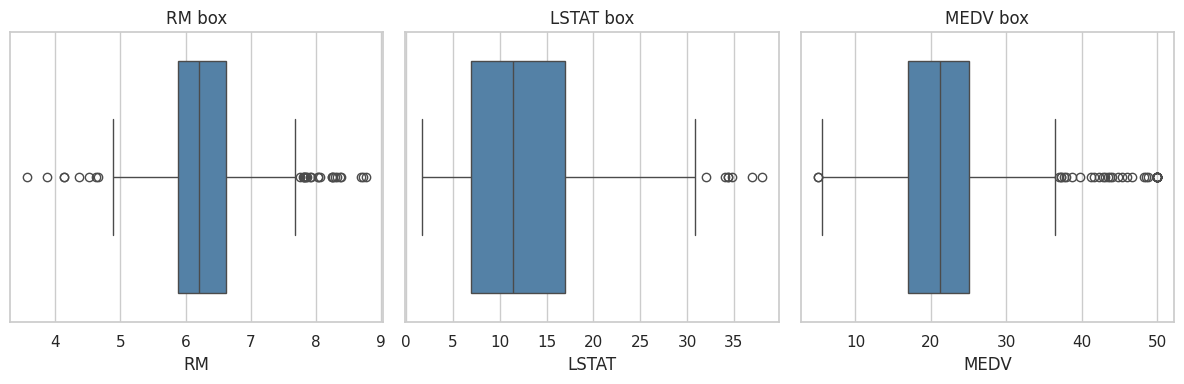

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["RM", "LSTAT", "MEDV"]):
    sns.boxplot(x=df[col], ax=ax, color="steelblue")
    ax.set_title(col + " box")
plt.tight_layout()
plt.show()


`LSTAT` and `MEDV` often look skewed. Real life piles up at one end. Mean is dramatic. Median is honest.


# 7. Countplot with hue

Make a cheap **price tag**: above-median `MEDV` = pricey neighborhood (for this dataset).

```python
df["Pricey"] = (df["MEDV"] > df["MEDV"].median()).astype(int)
```

Then: river towns vs not, split by pricey or not.


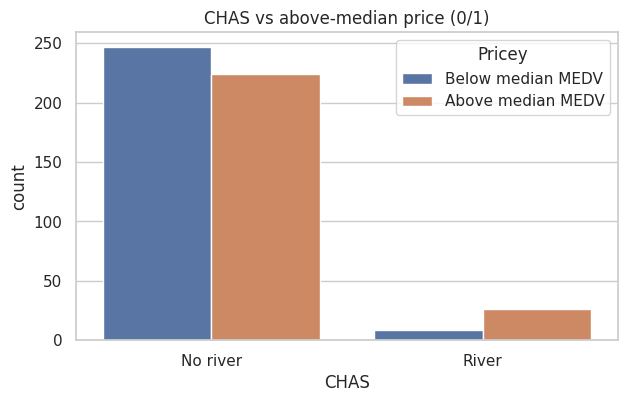

Pricey,0,1
CHAS,,
0,0.52,0.48
1,0.26,0.74


In [ ]:
df["Pricey"] = (df["MEDV"] > df["MEDV"].median()).astype(int)

sns.countplot(data=df, x="CHAS", hue="Pricey")
plt.xticks([0, 1], ["No river", "River"])
plt.legend(title="Pricey", labels=["Below median MEDV", "Above median MEDV"])
plt.title("CHAS vs above-median price (0/1)")
plt.show()

pd.crosstab(df["CHAS"], df["Pricey"], normalize="index").round(2)


# 8. Barplot — category vs number

**Barplot** = average of a numeric column per category.

Does river view (`CHAS`) get higher average `MEDV`? Does crime (`CRIM`) track with price if we bin towns? Start simple: mean `MEDV` by `CHAS`.


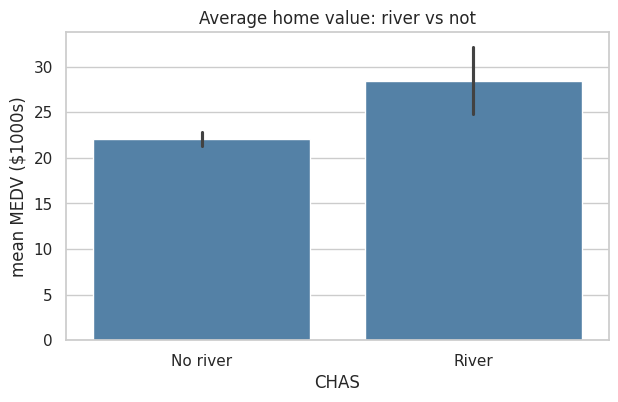

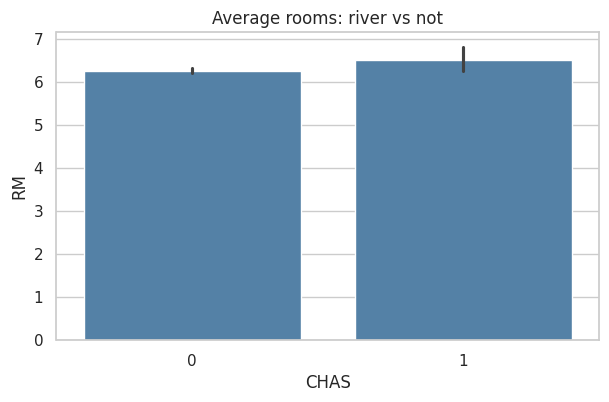

In [ ]:
sns.barplot(data=df, x="CHAS", y="MEDV", color="steelblue")
plt.xticks([0, 1], ["No river", "River"])
plt.ylabel("mean MEDV ($1000s)")
plt.title("Average home value: river vs not")
plt.show()

sns.barplot(data=df, x="CHAS", y="RM", color="steelblue")
plt.title("Average rooms: river vs not")
plt.show()


# 9. KDE — density

KDE = smooth histogram. Compare **where** values pile up.

- `LSTAT` for river vs not (`hue=CHAS`)
- `RM` for pricey vs not


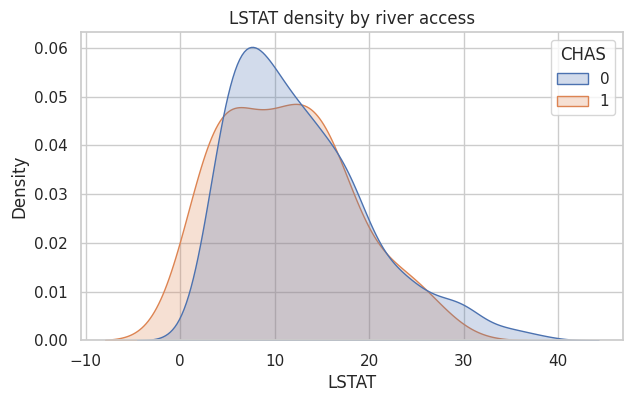

In [ ]:
sns.kdeplot(data=df, x="LSTAT", hue="CHAS", fill=True, common_norm=False)
plt.title("LSTAT density by river access")
plt.show()


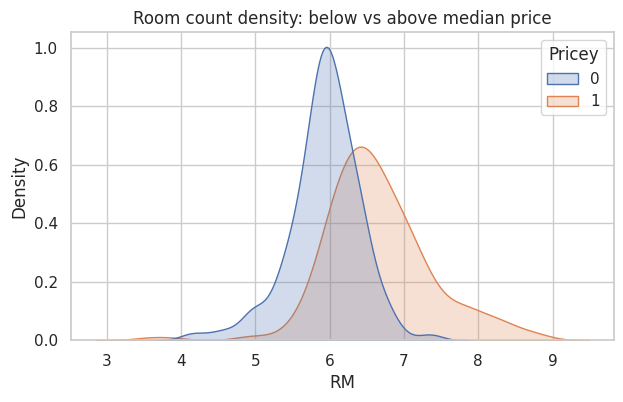

In [ ]:
sns.kdeplot(data=df, x="RM", hue="Pricey", fill=True, common_norm=False)
plt.title("Room count density: below vs above median price")
plt.show()


# 10. Scatterplot

Classic pair: **`RM` vs `LSTAT`**. Color by `MEDV` or `CHAS`.

More rooms + lower LSTAT often means pricier. EDA checks if the cloud agrees.


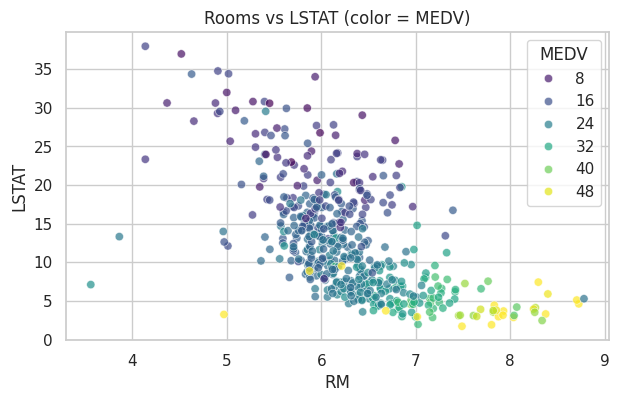

In [ ]:
sns.scatterplot(data=df, x="RM", y="LSTAT", hue="MEDV", palette="viridis", alpha=0.7)
plt.title("Rooms vs LSTAT (color = MEDV)")
plt.show()


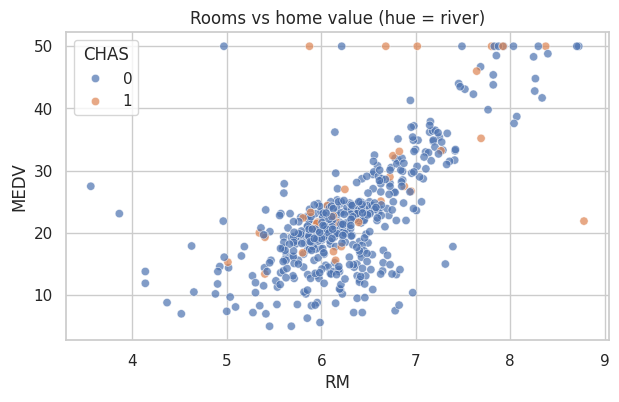

In [ ]:
sns.scatterplot(data=df, x="RM", y="MEDV", hue="CHAS", alpha=0.7)
plt.title("Rooms vs home value (hue = river)")
plt.show()


# 11. Y profiling (`MEDV`)

Profile the target:

- distribution (histogram)
- is it skewed?
- mean `MEDV` by `CHAS`
- quick correlation: `RM`, `LSTAT` vs `MEDV`


count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64


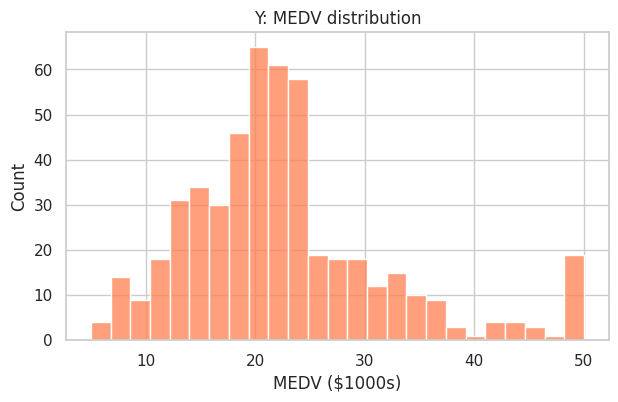

In [ ]:
y = df["MEDV"]
print(y.describe())
sns.histplot(y, bins=25, color="coral")
plt.title("Y: MEDV distribution")
plt.xlabel("MEDV ($1000s)")
plt.show()


In [ ]:
print("mean MEDV by CHAS:")
print(df.groupby("CHAS")["MEDV"].mean().round(2))

print("\ncorrelation with MEDV:")
print(df[["RM", "LSTAT", "NOX", "PTRATIO", "MEDV"]].corr()["MEDV"].sort_values(ascending=False))


mean MEDV by CHAS:
CHAS
0    22.09
1    28.44
Name: MEDV, dtype: float64

correlation with MEDV:
MEDV       1.000000
RM         0.695360
NOX       -0.427321
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64


---

# Pocket Recap

| Move | One line |
|------|----------|
| Load | `sep=r'\s+'`, pass column names |
| Y | `MEDV` in $1000s |
| EDA | look before `fit` |
| `CHAS` | 0/1 categorical |
| Hue | second variable as color |
| Barplot | category vs **mean** |
| KDE | smooth density, `hue` compares groups |
| Scatter | two numbers, optional color = Y |

Three things:

1. No header in `housing.csv` — names are on you.  
2. `CHAS` is rare (35 rows). Small groups lie quieter in plots.  
3. EDA is nosy. Nosy is the job.


---

# Practice — your turn

Use `df`. Already loaded.

## P1 — Screening (Easy)
Print shape, `df.info()`, and confirm zero missing.

## P2 — Categorical (Easy)
Countplot of `CHAS`. Print `value_counts(normalize=True)`.

## P3 — Numerical (Easy)
Histogram of `RM` and `MEDV` on one figure (two subplots).

## P4 — Hue (Medium)
Create `Pricey` (above median `MEDV`). Countplot `CHAS` with `hue=Pricey`. Print crosstab.

## P5 — Barplot (Medium)
Mean `MEDV` by `CHAS`. One sentence: river towns higher or lower on average?

## P6 — KDE (Medium)
KDE of `LSTAT` with `hue=CHAS`.

## P7 — Scatter (Medium)
Scatter `RM` vs `MEDV`, `hue=CHAS`. Print `groupby('CHAS')['MEDV'].mean()`.


In [ ]:
# P1


In [ ]:
# P2


In [ ]:
# P3


In [ ]:
# P4


In [ ]:
# P5


In [ ]:
# P6


In [ ]:
# P7


That is Boston housing EDA.

You looked. You plotted. You did not `fit` on row index.

Put `housing.csv` beside this notebook. Kaggle link in the first cell if you need a fresh copy.

See you at prediction week. Leave `inplace=True` alone.
